# TP1 — Prédire un nombre : la régression avec un réseau de neurones
**ÉNONCÉ** · Durée estimée : **une demi-journée**

## 🎯 Ce que vous allez apprendre
- La différence entre **régression** (prédire un nombre) et classification (prédire une catégorie)
- Pourquoi la dernière couche n'a **pas** d'activation, et pourquoi on utilise la perte **MSE**
- Lire **MAE, RMSE et R²** et savoir ce qu'ils disent
- Reconnaître le **sous-apprentissage** (réseau trop petit) et le surapprentissage (trop peu de données)
- Constater qu'**un réseau n'est pas toujours meilleur** qu'une méthode simple

## 🧰 Boîte à outils
Noms de fonctions et de classes utiles. **Aucun exemple d'appel n'est donné** : cherchez dans la documentation (scikit-learn, Keras, NumPy, matplotlib) comment les utiliser.

`np.random.default_rng`  ·  `plt.scatter`  ·  `train_test_split`  ·  `LinearRegression`  ·  `r2_score`  ·  `mean_absolute_error`  ·  `keras.Sequential`  ·  `layers.Dense`  ·  `model.compile`  ·  `model.fit`  ·  `model.predict`  ·  `StandardScaler`  ·  `load_diabetes`

## 📘 Comment travailler
- Les cellules **déjà écrites** sont à lire et à exécuter.
- Les cellules **🎯 Étape** sont à **écrire vous-même**, à partir de la consigne.
- Après chaque étape, une cellule **✅ Contrôle** vérifie votre résultat. Respectez les **noms de variables** demandés.
- Les questions **✍️** demandent une réponse écrite : c'est là que vous montrez que vous avez compris.
- Bloqué ? Relisez l'indice, puis cherchez dans la documentation. Un message d'erreur se lit : la dernière ligne dit souvent ce qui ne va pas.

In [1]:
pip install scikit-learn pandas matplotlib tensorflow

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, confusion_matrix, precision_score, recall_score
from tensorflow import keras
from tensorflow.keras import layers, regularizers
keras.utils.set_random_seed(42)

def controle(condition, ok, ko):
    print("✅", ok) if condition else print("❌", ko)

I0000 00:00:1792154970.949231  310144 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792154972.094193  310144 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


## Étape 1 — Les données : une courbe et du bruit
En **régression**, on prédit un **nombre** (ici la hauteur `y` d'une courbe à partir de sa position `x`). Nous fabriquons les données nous-mêmes : un sinus, plus un peu de bruit aléatoire. Une **droite** ne pourra pas suivre cette courbe, un **réseau** si.

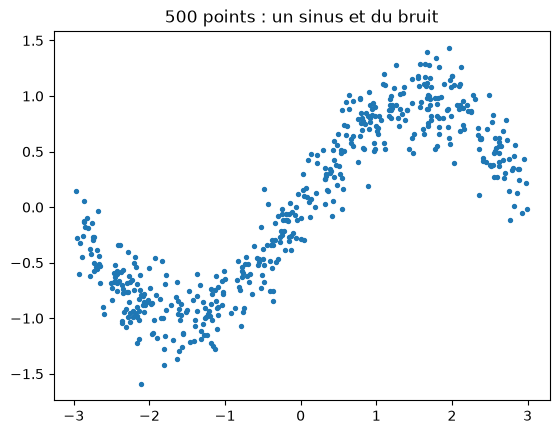

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# 1. On initialise le générateur de nombres aléatoires avec une "graine" (le chiffre 42).
# Cela permet de figer le hasard : à chaque fois que tu relanceras ce code, 
# tu obtiendras exactement les mêmes points aléatoires (très utile pour comparer nos résultats).
rng = np.random.default_rng(42)

# 2. On crée 500 positions sur l'axe horizontal (l'axe des x).
# Ces valeurs sont choisies au hasard de manière uniforme (réparties équitablement) entre -3 et 3.
x = rng.uniform(-3, 3, 500)

# 3. On calcule la hauteur correspondante (l'axe des y) pour chaque position x.
# Pour cela, on applique la formule mathématique du "sinus" (np.sin(x)), 
# à laquelle on ajoute un petit "bruit" aléatoire (une variation de type loi normale, 
# centrée sur 0 avec une dispersion de 0.2). 
# Ce bruit simule des imperfections réalistes, comme si on mesurait des données dans la vraie vie.
y = np.sin(x) + rng.normal(0, 0.2, 500)

# 4. On dessine le graphique sous la forme d'un nuage de points (fonction "scatter").
# - 'x' et 'y' représentent les coordonnées de chaque point.
# - 's=8' définit la petite taille des points affichés.
plt.scatter(x, y, s=8)

# 5. On ajoute un titre au graphique, puis on l'affiche à l'écran.
plt.title("500 points : un sinus et du bruit")
plt.show()

## 🎯 Étape 2 — Découper en apprentissage et test
On garde **20 % des points de côté** : le réseau ne les verra jamais pendant l'apprentissage. Ils serviront de verdict final. Keras attend des entrées **à 2 dimensions** : `x` doit devenir un tableau de forme `(500, 1)`.

**À faire :** Faites `X` (500 lignes, 1 colonne) à partir de `x`, puis découpez en `x_train`, `x_test`, `y_train`, `y_test` : **20 % de test**, `random_state=42`.

> 💡 **Indice** : `reshape(-1, 1)` met un vecteur en colonne. `train_test_split` renvoie 4 morceaux dans un ordre précis : lisez sa documentation.

In [9]:
# On redimensionne le vecteur x pour qu'il devienne un tableau à 2 dimensions (500 lignes, 1 colonne).
# C'est un format obligatoire exigé par Keras et les couches de neurones en entrée.
x = x.reshape(-1, 1)

# On découpe nos données en deux jeux distincts :
# - 80 % pour l'apprentissage (x_train, y_train)
# - 20 % pour le test final (x_test, y_test)
# Le paramètre random_state=42 fige le hasard pour que le découpage soit reproductible à l'identique.
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [10]:
# ✅ Contrôle (ne pas modifier)
controle(x_train.shape == (400, 1) and x_test.shape == (100, 1), 'Découpage correct : 400 / 100', 'Attendu (400, 1) et (100, 1)')

✅ Découpage correct : 400 / 100


## 🎯 Étape 3 — La référence : une droite
Avant tout réseau, on regarde ce que fait **la méthode la plus simple** : une droite. Le **R²** mesure la part de variation expliquée : **1 = parfait, 0 = pas mieux que prédire toujours la moyenne**.

**À faire :** Entraînez une régression linéaire sur `x_train`, puis calculez son **R² sur le test** dans une variable `r2_lineaire`.

> 💡 **Indice** : `LinearRegression`, ses méthodes `fit` et `predict`, puis `r2_score(vrais, prédits)`.

In [11]:
from sklearn.linear_model import LinearRegression
# TODO : calculer r2_lineaire


# 1. On instancie le modèle de régression linéaire
modele_lineaire = LinearRegression()

# 2. On entraîne le modèle sur les données d'apprentissage (x_train et y_train)
modele_lineaire.fit(x_train, y_train)

# 3. On prédit les valeurs sur le jeu de test (x_test)
y_pred_lineaire = modele_lineaire.predict(x_test)

# 4. On calcule le score R² en comparant les vraies valeurs (y_test) et les prédictions (y_pred_lineaire)
r2_lineaire = r2_score(y_test, y_pred_lineaire)

# On affiche le résultat pour information
print("Score R² de la droite :", round(r2_lineaire, 3))

Score R² de la droite : 0.653


In [12]:
# ✅ Contrôle (ne pas modifier)
controle(0.5 < r2_lineaire < 0.8, 'R² de la droite plausible', 'Attendu un R² entre 0.5 et 0.8 : une droite explique une partie seulement de la courbe')

✅ R² de la droite plausible


## 🎯 Étape 4 — Construire le réseau
Un réseau de régression ressemble à celui d'une classification, avec **deux différences** : la **dernière couche n'a pas d'activation** (elle doit pouvoir sortir n'importe quel nombre, pas seulement entre 0 et 1), et la **perte** est la **MSE** (erreur quadratique moyenne : la moyenne des carrés des écarts).

**À faire :** Construisez `modele` : entrée de taille 1, **deux couches cachées de 32 neurones (ReLU)**, **une sortie de 1 neurone sans activation**. Compilez avec l'optimiseur **adam**, la perte **mse** et la métrique **mae**. Affichez le résumé.

> 💡 **Indice** : `keras.Sequential([...])`, `layers.Input`, `layers.Dense`, `model.compile`, `model.summary`.

In [13]:
keras.utils.set_random_seed(42)
# TODO : construire et compiler modele
keras.utils.set_random_seed(42)

# 1. On construit le modèle séquentiel en empilant les couches
modele = keras.Sequential([
    layers.Input(shape=(1,)),                   # L'entrée : 1 seule caractéristique (la valeur de x)
    layers.Dense(32, activation="relu"),        # 1ère couche cachée de 32 neurones avec activation ReLU
    layers.Dense(32, activation="relu"),        # 2e couche cachée de 32 neurones avec activation ReLU
    layers.Dense(1)                             # La couche de sortie : 1 seul neurone, sans fonction d'activation (pour pouvoir prédire n'importe quelle valeur réelle)
])

# 2. On compile le modèle en choisissant l'optimiseur, la fonction de perte et la métrique
modele.compile(
    optimizer="adam",                           # L'optimiseur pour ajuster les poids
    loss="mse",                                 # La perte : Mean Squared Error (erreur quadratique moyenne)
    metrics=["mae"]                             # La métrique de suivi : Mean Absolute Error (erreur absolue moyenne)
)

# 3. On affiche le résumé de l'architecture du réseau et de ses paramètres
modele.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,153 (4.50 KB)

 Trainable params: 1,153 (4.50 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
# ✅ Contrôle (ne pas modifier)
controle(modele.count_params() == 1153, 'Réseau correct : 1 153 paramètres', 'Attendu 1 153 paramètres, obtenu ' + str(modele.count_params()) + ' : vérifiez les couches')

✅ Réseau correct : 1 153 paramètres


## 🎯 Étape 5 — Entraîner
Un **epoch** est un passage complet sur les données d'apprentissage. On met aussi **20 % de l'apprentissage de côté** (`validation_split`) : à chaque epoch, on mesure l'erreur sur ces points que le réseau n'utilise pas pour se corriger.

**À faire :** Entraînez `modele` : **200 epochs**, **batch de 32**, **20 % de validation**, sans affichage. Stockez le résultat dans `histoire`.

> 💡 **Indice** : `model.fit(...)` renvoie un objet « historique ». Cherchez les arguments `epochs`, `batch_size`, `validation_split`, `verbose`.

In [15]:
# TODO : entraîner modele et stocker le résultat dans histoire
# On entraiine le modèle sur les données d'apprentissage
histoire = modele.fit(
    x_train, y_train,                  # Les données et les valeurs cibles d'apprentissage
    epochs=200,                        # Nombre de passages complets sur tout l'apprentissage
    batch_size=32,                     # Nombre d'exemples traités avant chaque mise à jour des poids
    validation_split=0.2,              # 20 % des données d'apprentissage mises de côté pour surveiller l'erreur
    verbose=0                          # Désactive l'affichage ligne par ligne pendant l'entraînement
)
print("Entraînement terminé avec succès !")

Entraînement terminé avec succès !


In [16]:
# ✅ Contrôle (ne pas modifier)
controle(len(histoire.history['loss']) == 200, '200 epochs effectués', 'Attendu 200 epochs')

✅ 200 epochs effectués


## Étape 6 — Lire la courbe de perte
La perte (MSE) doit **baisser puis se stabiliser**. La courbe orange (validation) est notre détecteur de triche.

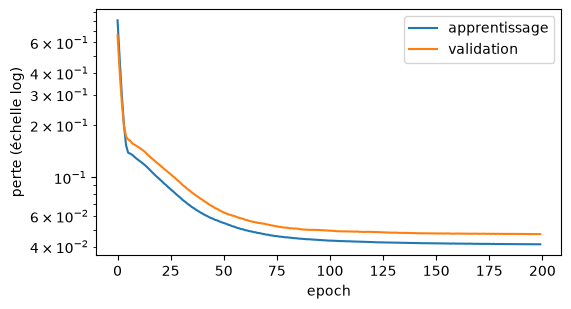

In [17]:
plt.figure(figsize=(6, 3.2))
plt.plot(histoire.history["loss"], label="apprentissage"); plt.plot(histoire.history["val_loss"], label="validation")
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("perte (échelle log)"); plt.legend(); plt.show()

### ✍️ Question
**À partir de quel epoch environ la courbe devient-elle plate ? Les 200 epochs étaient-ils nécessaires ?**

*Votre réponse (2 à 4 lignes) :*

> La courbe commence à devenir plate et à se stabiliser autour des epochs 100 à 125. Par conséquent, les 200 epochs n'étaient pas strictement nécessaires, le modèle ayant atteint sa phase de convergence optimale bien avant cette limite.

## 🎯 Étape 7 — Évaluer : trois mesures de l'erreur
Sur le test, trois chiffres complémentaires :
- **MAE** : l'erreur moyenne, dans l'unité de `y` (facile à expliquer à un non-spécialiste) ;
- **RMSE** : comme la MAE, mais les **grosses erreurs pèsent plus** ;
- **R²** : de 0 à 1, la part de variation expliquée.

**À faire :** Prédisez `y_pred` sur `x_test` (tableau à une dimension), puis calculez `r2_reseau`, `mae` et `rmse`. Le RMSE est la racine de la moyenne des carrés des écarts.

> 💡 **Indice** : `model.predict(...)` renvoie un tableau à 2 dimensions : `.ravel()` le met à plat. `mean_absolute_error`, `r2_score`, `np.sqrt`, `np.mean`.

In [18]:
# TODO : calculer y_pred, r2_reseau, mae, rmse
# 1. On prédit les valeurs sur le jeu de test et on aplatit le tableau à 2 dimensions en 1D avec .ravel()
y_pred = modele.predict(x_test).ravel()

# 2. On calcule le score R² (part de variation expliquée)
r2_reseau = r2_score(y_test, y_pred)

# 3. On calcule la MAE (Mean Absolute Error : l'erreur moyenne en valeur absolue)
mae = mean_absolute_error(y_test, y_pred)

# 4. On calcule le RMSE (Root Mean Squared Error : racine carrée de la moyenne des erreurs quadratiques)
rmse = np.sqrt(np.mean((y_test - y_pred) ** 2))

# Affichage des métriques pour vérification
print(f"R² du réseau : {r2_reseau:.3f}")
print(f"MAE : {mae:.3f}")
print(f"RMSE : {rmse:.3f}")

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
R² du réseau : 0.933
MAE : 0.163
RMSE : 0.204


In [19]:
# ✅ Contrôle (ne pas modifier)
controle(r2_reseau > 0.85 and r2_reseau > r2_lineaire, 'Le réseau bat la droite', 'Attendu un R² du réseau supérieur à 0.85 et à celui de la droite')

✅ Le réseau bat la droite


## Étape 8 — Voir ce que le réseau a appris
On trace la courbe prédite par le réseau (rouge) contre la vraie courbe (gris pointillé). C'est la meilleure façon de **comprendre** ce qu'un modèle a fait.

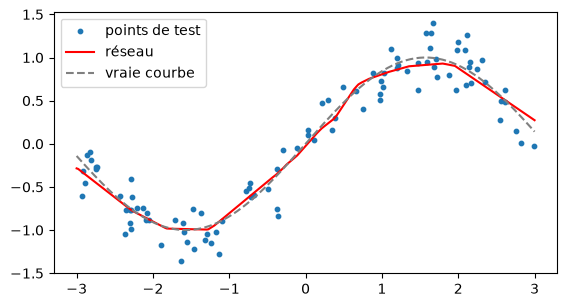

In [20]:
xs = np.linspace(-3, 3, 300).reshape(-1, 1)
plt.figure(figsize=(6.5, 3.4))
plt.scatter(x_test, y_test, s=10, label="points de test")
plt.plot(xs, modele.predict(xs, verbose=0), color="red", label="réseau")
plt.plot(xs, np.sin(xs), "--", color="gray", label="vraie courbe")
plt.legend(); plt.show()

## 🎯 Étape 9 — Expérience : combien de neurones faut-il ?
Un réseau trop petit ne peut pas suivre la courbe : c'est le **sous-apprentissage**. Mesurons-le.

**À faire :** Pour des réseaux à **une seule couche cachée** de **1, 4, 32 puis 256 neurones** (200 epochs, batch 32, sans validation), calculez le **R² sur le test**. Rangez les résultats dans un dictionnaire `resultats` (clé = nombre de neurones). Tracez les 4 courbes prédites côte à côte.

> 💡 **Indice** : Une boucle `for n in (1, 4, 32, 256)`. Pensez à refixer la graine (`set_random_seed`) à chaque tour pour comparer à armes égales.

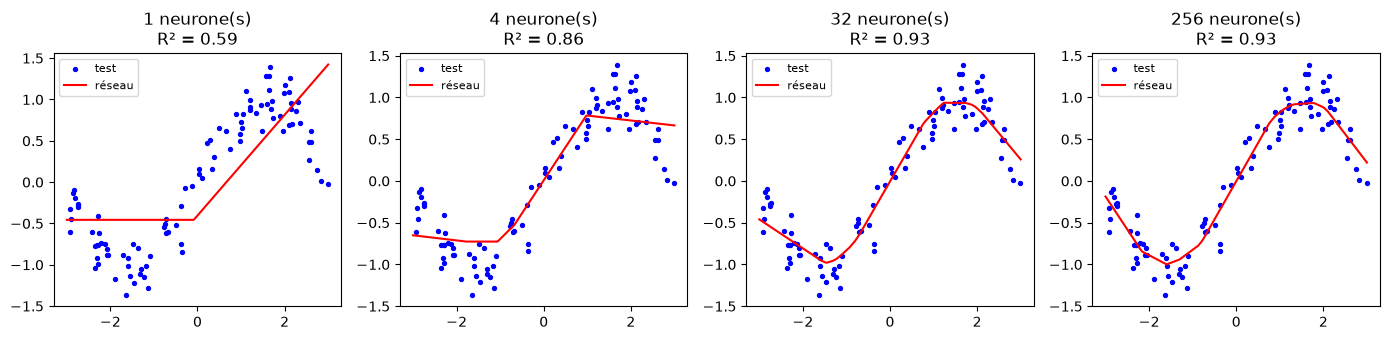

Dictionnaire des résultats (R²) : {1: 0.5898929967956706, 4: 0.8569617593116818, 32: 0.9264694296133505, 256: 0.9348530053069218}


In [21]:
resultats = {}
# TODO : boucle sur 1, 4, 32, 256 neurones
# 1. On initialise le dictionnaire pour stocker les résultats et une figure pour afficher les sous-graphes
resultats = {}
plt.figure(figsize=(14, 3.5))

# Liste des tailles de couches cachées à tester
neurones_list = [1, 4, 32, 256]

for i, n in enumerate(neurones_list):
    # On fixe la graine à chaque tour pour garantir l'équité de l'initialisation aléatoire
    keras.utils.set_random_seed(42)
    
    # 2. Construction du modèle avec une seule couche cachée de n neurones
    modele_exp = keras.Sequential([
        layers.Input(shape=(1,)),
        layers.Dense(n, activation="relu"),
        layers.Dense(1)
    ])
    
    # Compilation
    modele_exp.compile(optimizer="adam", loss="mse")
    
    # 3. Entraînement (200 epochs, batch de 32, sans validation_split)
    modele_exp.fit(x_train, y_train, epochs=200, batch_size=32, verbose=0)
    
    # 4. Calcul du score R² sur le jeu de test
    y_pred_exp = modele_exp.predict(x_test, verbose=0).ravel()
    score_r2 = r2_score(y_test, y_pred_exp)
    resultats[n] = score_r2
    
    # 5. Affichage des courbes côte à côte (1 ligne, 4 colonnes)
    plt.subplot(1, 4, i + 1)
    plt.scatter(x_test, y_test, s=8, label="test", color="blue")
    
    # Tracé de la courbe prédite par le réseau
    xs = np.linspace(-3, 3, 300).reshape(-1, 1)
    plt.plot(xs, modele_exp.predict(xs, verbose=0), color="red", label="réseau")
    
    plt.title(f"{n} neurone(s)\nR² = {score_r2:.2f}")
    plt.legend(loc="upper left", fontsize=8)

plt.tight_layout()
plt.show()

# Affichage du dictionnaire de résultats
print("Dictionnaire des résultats (R²) :", resultats)

In [22]:
# ✅ Contrôle (ne pas modifier)
controle(len(resultats) == 4 and resultats[1] < resultats[32], 'Un seul neurone fait moins bien que 32', 'Attendu 4 résultats, avec R² de 1 neurone < R² de 32 neurones')

✅ Un seul neurone fait moins bien que 32


### ✍️ Question
**Que se passe-t-il avec un seul neurone ? Passer de 32 à 256 neurones change-t-il beaucoup le résultat ?**

*Votre réponse (2 à 4 lignes) :*

> Avec un seul neuronne, le modèle subit un fort sous-apprentissage : il se réduit à une simple droite incapable de capturer les variations de la courbe sinusoïdale. En revanche, passer de 32 à 256 neurones ne change pas enormement le résultat visuel ou les performances, la complexité apportée par 32 neurones étant déjà amplement suffisante pour modéliser ce phénomène.

## 🎯 Étape 10 — Expérience : trop peu de données
Cette fois c'est l'inverse : un **gros** réseau (2 couches de 256 neurones) mais **très peu de données**. Il peut alors mémoriser chaque point, bruit compris : c'est le **surapprentissage**.

**À faire :** N'utilisez que les **15 premiers points** de `x_train` / `y_train`. Entraînez le gros réseau **500 epochs** (batch 8). Calculez `r2_train` (sur ces 15 points) et `r2_test` (sur tout le test). Tracez la courbe prédite.

> 💡 **Indice** : Découpez avec `x_train[:15]`. Comparez les deux R² : que valent-ils chacun ?

R² sur les 15 points d'entraînement : 0.974
R² sur le test : 0.793


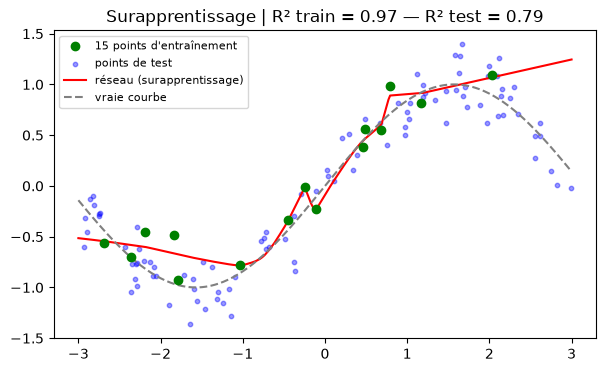

In [23]:
# TODO : calculer r2_train et r2_test avec seulement 15 points
# 1. On ne garde que les 15 premiers points des données d'apprentissage
x_train_15 = x_train[:15]
y_train_15 = y_train[:15]

# 2. On fixe la graine pour la reproductibilité
keras.utils.set_random_seed(42)

# 3. Construction du "gros" réseau : 2 couches cachées de 256 neurones
modele_overfit = keras.Sequential([
    layers.Input(shape=(1,)),
    layers.Dense(256, activation="relu"),
    layers.Dense(256, activation="relu"),
    layers.Dense(1)
])

# Compilation
modele_overfit.compile(optimizer="adam", loss="mse")

# 4. Entraînement sur les 15 points (500 epochs, batch de 8)
modele_overfit.fit(x_train_15, y_train_15, epochs=500, batch_size=8, verbose=0)

# 5. Calcul des scores R²
# Sur les 15 points d'entraînement (le modèle a mémorisé par cœur)
y_pred_train_15 = modele_overfit.predict(x_train_15, verbose=0).ravel()
r2_train = r2_score(y_train_15, y_pred_train_15)

# Sur tout le jeu de test (le modèle échoue à généraliser)
y_pred_test = modele_overfit.predict(x_test, verbose=0).ravel()
r2_test = r2_score(y_test, y_pred_test)

print(f"R² sur les 15 points d'entraînement : {r2_train:.3f}")
print(f"R² sur le test : {r2_test:.3f}")

# 6. Tracé de la courbe prédite
plt.figure(figsize=(7, 4))
plt.scatter(x_train_15, y_train_15, color="green", label="15 points d'entraînement", zorder=5)
plt.scatter(x_test, y_test, color="blue", s=10, label="points de test", alpha=0.4)

xs = np.linspace(-3, 3, 300).reshape(-1, 1)
plt.plot(xs, modele_overfit.predict(xs, verbose=0), color="red", label="réseau (surapprentissage)")
plt.plot(xs, np.sin(xs), "--", color="gray", label="vraie courbe")

plt.title(f"Surapprentissage | R² train = {r2_train:.2f} — R² test = {r2_test:.2f}")
plt.legend(fontsize=8)
plt.show()

In [24]:
# ✅ Contrôle (ne pas modifier)
controle(r2_train > r2_test, 'R² d\'apprentissage supérieur au R² de test : signe de surapprentissage', 'Attendu r2_train > r2_test')

✅ R² d'apprentissage supérieur au R² de test : signe de surapprentissage


### ✍️ Question
**Comparez R² d'apprentissage et R² de test. Que vous dit l'écart ? Que faudrait-il pour le réduire ?**

*Votre réponse (2 à 4 lignes) :*

> Le R^2 d'apprentissage (0.97) est supérieur au R^2 de test (0.79), ce qui met en évidence un surapprentissage : le modèle a mémorisé les points d'entraînement spécifiques au lieu de généraliser. Pour réduire cet écart, il faudrait augmenter la quantité de données d'entraînement ou intégrer des techniques de régularisation.

## 🎯 Étape 11 — Sur des données réelles : la progression du diabète
Reprenez **toute la démarche** sur un vrai jeu : `load_diabetes` (442 patients, 10 mesures médicales, cible = indice de progression de la maladie). Ici les 10 colonnes ont des échelles différentes : il faut les **mettre à l'échelle**, en calculant la moyenne et l'écart-type **sur l'apprentissage seul**.

**À faire :** 1) Découpez (20 % de test, `random_state=42`) vers `Xd_train`, `Xd_test`, `yd_train`, `yd_test`. 2) Standardisez (fit sur train, transform sur train et test). 3) Régression linéaire → `r2_lin_d`. 4) Réseau **16 puis 8 neurones**, 150 epochs max, batch 16, validation 20 %, **arrêt précoce** (patience 15, `restore_best_weights=True`) → `r2_res_d`.

> 💡 **Indice** : `StandardScaler` : `fit` puis `transform`. `keras.callbacks.EarlyStopping`. Pour un réseau de régression, rappelez-vous la sortie et la perte.

In [25]:
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
# TODO : tout le pipeline sur le jeu du diabète
from sklearn.preprocessing import StandardScaler

# 1. Chargement des données du diabète
diabetes = load_diabetes()
X_d, y_d = diabetes.data, diabetes.target

# 2. Découpage en apprentissage et test (20% de test, random_state=42)
Xd_train, Xd_test, yd_train, yd_test = train_test_split(X_d, y_d, test_size=0.2, random_state=42)

# 3. Standardisation : calcul de la moyenne et de l'écart-type uniquement sur le train, puis application sur train et test
scaler = StandardScaler()
Xd_train_scaled = scaler.fit_transform(Xd_train)
Xd_test_scaled = scaler.transform(Xd_test)

# 4. Régression linéaire de référence
modele_lin_d = LinearRegression()
modele_lin_d.fit(Xd_train_scaled, yd_train)
yd_pred_lin = modele_lin_d.predict(Xd_test_scaled)
r2_lin_d = r2_score(yd_test, yd_pred_lin)

# 5. Réseau de neurones (16 puis 8 neurones) avec arrêt précoce
keras.utils.set_random_seed(42)

modele_res_d = keras.Sequential([
    layers.Input(shape=(Xd_train_scaled.shape[1],)),
    layers.Dense(16, activation="relu"),
    layers.Dense(8, activation="relu"),
    layers.Dense(1)  # Sortie unique pour la régression
])

modele_res_d.compile(optimizer="adam", loss="mse")

# Configuration de l'arrêt précoce (patience de 15 epochs, restauration des meilleurs poids)
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", 
    patience=15, 
    restore_best_weights=True
)

# Entraînement avec 150 epochs max, batch de 16, et 20% de validation
modele_res_d.fit(
    Xd_train_scaled, yd_train,
    epochs=150,
    batch_size=16,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=0
)

# 6. Évaluation du réseau sur le test
yd_pred_res = modele_res_d.predict(Xd_test_scaled, verbose=0).ravel()
r2_res_d = r2_score(yd_test, yd_pred_res)

# Affichage des résultats finaux
print(f"Score R² de la régression linéaire : {r2_lin_d:.3f}")
print(f"Score R² du réseau de neurones : {r2_res_d:.3f}")

Score R² de la régression linéaire : 0.453
Score R² du réseau de neurones : 0.463


In [26]:
# ✅ Contrôle (ne pas modifier)
controle(0.3 < r2_lin_d < 0.6 and 0.3 < r2_res_d < 0.6, 'Résultats plausibles sur le diabète', 'Attendu des R² entre 0.3 et 0.6 pour les deux méthodes')

✅ Résultats plausibles sur le diabète


### ✍️ Question
**Le réseau bat-il nettement la régression linéaire ? Pourquoi l'avantage est-il faible sur ce jeu ?**

*Votre réponse (2 à 4 lignes) :*

> Non, le réseau ne bat pas nettement la régression linéaire, les scores R^2 étant très proches (environ 0,45 contre 0,46). Cet avantage minime s'explique par le fait que les relations dans ce jeu de données médical sont en grande partie linéaires, et que la taille restreinte de l'échantillon ne permet pas à un réseau de neurones de surperformer massivement.

## ✅ Ce qu'il faut retenir
- **Régression** = prédire un nombre : sortie **sans activation**, perte **MSE**, mesures **MAE / RMSE / R²**.
- Le **R²** se lit par rapport à une référence : 0 = pas mieux que la moyenne, 1 = parfait. Comparez **toujours** à une méthode simple.
- **Trop petit** = sous-apprentissage ; **trop gros pour trop peu de données** = surapprentissage.
- Un réseau **n'est pas toujours meilleur** : sur peu de données ou une relation simple, une droite suffit.